In [2]:
# ============================================================
  # FASE 1 - CONFIGURAÇÃO E IMPORTAÇÃO
  # ============================================================

  # Importamos a biblioteca pandas para carregar e manipular dados
import pandas as pd

  # Importamos numpy para operações matemáticas sobre arrays
import numpy as np

  # Importamos matplotlib para criar gráficos básicos
import matplotlib.pyplot as plt

  # Importamos seaborn para gráficos estatísticos mais elaborados
import seaborn as sns

  # Confirmação visual de que as importações correram bem
print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [3]:
# Carregamos o ficheiro CSV e transformamo-lo num DataFrame
# O pandas lê o ficheiro linha a linha e organiza tudo numa tabela virtual
df = pd.read_csv("cumulative.csv")

# Confirmação de que o ficheiro foi lido com sucesso
print("Dataset carregado com sucesso!")

Dataset carregado com sucesso!


In [4]:
# df.shape devolve um par de números: (número de linhas, número de colunas)                                   
# É a primeira pergunta que um Cientista de Dados faz ao dataset                                              
print("Dimensões do dataset:", df.shape)

Dimensões do dataset: (9564, 50)


In [5]:
# df.info() mostra-nos:
# - o nome de cada coluna
# - quantos valores não-nulos existem (se for menor que 9564, há NaN nessa coluna)
# - o tipo de dado: int64 (inteiro), float64 (decimal), object (texto)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9564 entries, 0 to 9563
Data columns (total 50 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   rowid              9564 non-null   int64  
 1   kepid              9564 non-null   int64  
 2   kepoi_name         9564 non-null   str    
 3   kepler_name        2294 non-null   str    
 4   koi_disposition    9564 non-null   str    
 5   koi_pdisposition   9564 non-null   str    
 6   koi_score          8054 non-null   float64
 7   koi_fpflag_nt      9564 non-null   int64  
 8   koi_fpflag_ss      9564 non-null   int64  
 9   koi_fpflag_co      9564 non-null   int64  
 10  koi_fpflag_ec      9564 non-null   int64  
 11  koi_period         9564 non-null   float64
 12  koi_period_err1    9110 non-null   float64
 13  koi_period_err2    9110 non-null   float64
 14  koi_time0bk        9564 non-null   float64
 15  koi_time0bk_err1   9110 non-null   float64
 16  koi_time0bk_err2   9110 non-null   

In [6]:
# df.head() mostra as primeiras 5 linhas do DataFrame
# É como abrir o ficheiro Excel e ver o topo da tabela
df.head()

,rowid,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,1,10797460,K00752.01,Kepler-227 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
1,2,10797460,K00752.02,Kepler-227 c,CONFIRMED,CANDIDATE,0.969,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
2,3,10811496,K00753.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-176.0,4.544,0.044,-0.176,0.868,0.233,-0.078,297.00482,48.134129,15.436
3,4,10848459,K00754.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-174.0,4.564,0.053,-0.168,0.791,0.201,-0.067,285.53461,48.285210,15.597
4,5,10854555,K00755.01,Kepler-664 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-211.0,4.438,0.070,-0.210,1.046,0.334,-0.133,288.75488,48.226200,15.509


In [7]:
# Vamos ver quais os valores únicos que existem na coluna Target                                              
# Esta coluna é o que a IA vai aprender a prever                                                                print("Valores únicos no Target:")                                                                              print(df["koi_disposition"].unique())                                                                         

print("\nContagem de cada classe:")
print(df["koi_disposition"].value_counts())


Contagem de cada classe:
koi_disposition
FALSE POSITIVE    5023
CONFIRMED         2293
CANDIDATE         2248
Name: count, dtype: int64


=== Distribuição das Classes ===
FALSE POSITIVE : 5023 observações (52.5%)
CONFIRMED : 2293 observações (24.0%)
CANDIDATE : 2248 observações (23.5%)


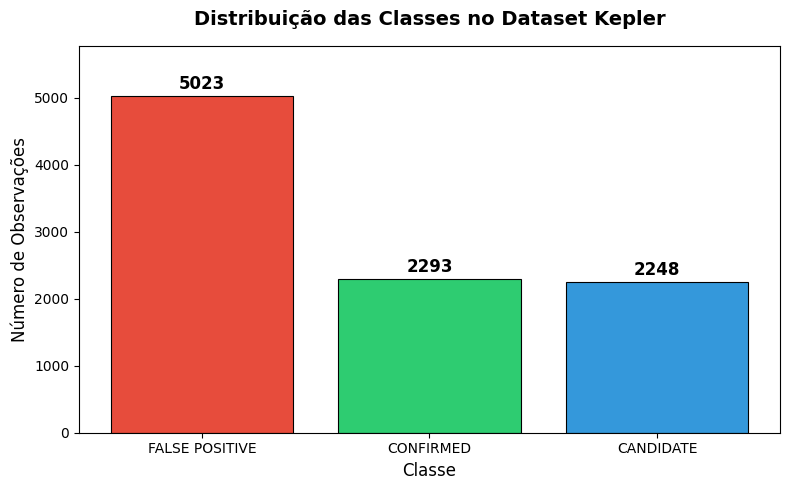

In [8]:
 # ============================================================
2 # FASE 2 - ANÁLISE EXPLORATÓRIA DE DADOS (EDA)
 # Passo 1: Análise de Desequilíbrio de Classes                                                                                                                                                                               4 # ============================================================
                                                                                                                                                                                                                    
# Contamos quantos exemplos existem de cada classe                                                                                                                                                                  
contagem_classes = df["koi_disposition"].value_counts()

 # Calculamos a percentagem de cada classe em relação ao total
percentagens = df["koi_disposition"].value_counts(normalize=True) * 100

print("=== Distribuição das Classes ===")
for classe, count in contagem_classes.items():
    print(f"{classe} : {count} observações ({percentagens[classe] :.1f}%)")
# Criamos uma figura com tamanho 8x5 polegadas
fig, ax = plt.subplots(figsize=(8, 5))
 # Definimos cores distintas para cada classe
cores = ["#e74c3c", "#2ecc71", "#3498db"]

 # Desenhamos o gráfico de barras
barras = ax.bar(contagem_classes.index, contagem_classes.values, color=cores, edgecolor="black", linewidth=0.8)
 # Adicionamos o número exato em cima de cada barra
for barra in barras:
     altura = barra.get_height()
     ax.text(
         barra.get_x() + barra.get_width() / 2,  # posição x: centro da barra
         altura + 50,   # posição y: ligeiramente acima da barra
         f"{int(altura)}",                         # texto: o número inteiro
         ha="center", va="bottom", fontsize=12, fontweight="bold"     )

 # Títulos e legendas
ax.set_title("Distribuição das Classes no Dataset Kepler", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Classe", fontsize=12)
ax.set_ylabel("Número de Observações", fontsize=12)
ax.set_ylim(0, contagem_classes.max() * 1.15)  # margem no topo para os números

plt.tight_layout()
plt.show()


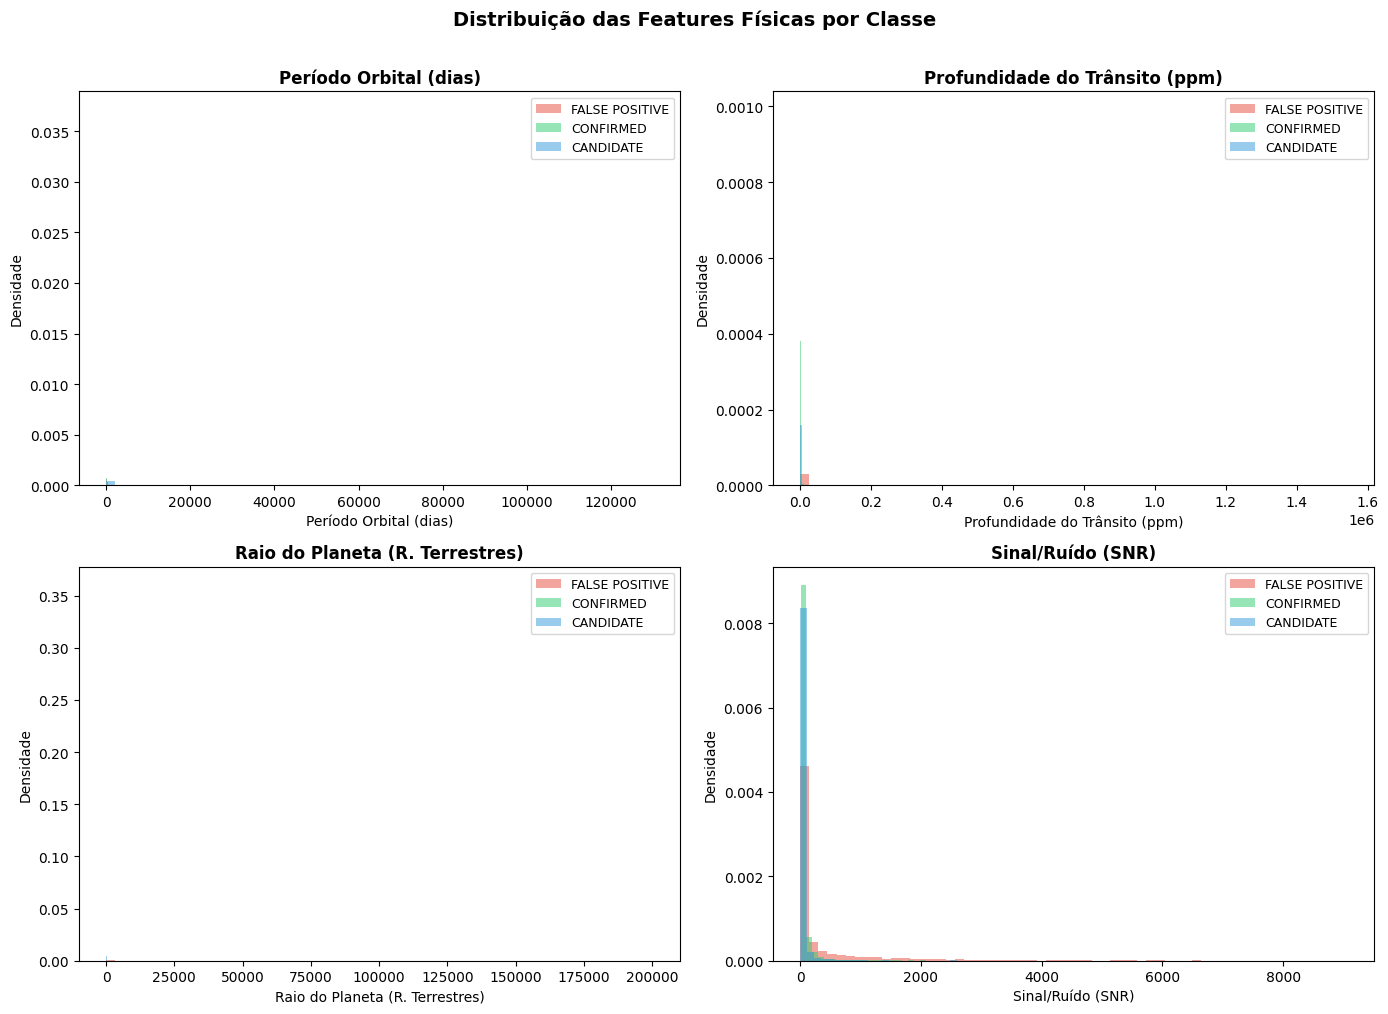

In [9]:
  # ============================================================                                                                                                                                                                 # FASE 2 - Passo 2: Histogramas das Features Físicas                                                                                                                                                                         
  # ============================================================                                                                                                                                                               
  
features = ["koi_period", "koi_depth", "koi_prad", "koi_model_snr"]

nomes = ["Período Orbital (dias)", "Profundidade do Trânsito (ppm)", "Raio do Planeta (R. Terrestres)", "Sinal/Ruído (SNR)"]

cores_classes = {
      "FALSE POSITIVE": "#e74c3c",
      "CONFIRMED":      "#2ecc71",
      "CANDIDATE":      "#3498db"
  }

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, feature, nome in zip(axes.flatten(), features, nomes):

    for classe, cor in cores_classes.items():
        dados_classe = df[df["koi_disposition"] == classe][feature].dropna()
        ax.hist(
            dados_classe,
            bins=60,
            color=cor,
            alpha=0.5,
            label=classe,
            density=True
        )

    ax.set_title(nome, fontsize=12, fontweight="bold")
    ax.set_xlabel(nome, fontsize=10)
    ax.set_ylabel("Densidade", fontsize=10)
    ax.legend(fontsize=9)

plt.suptitle("Distribuição das Features Físicas por Classe", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

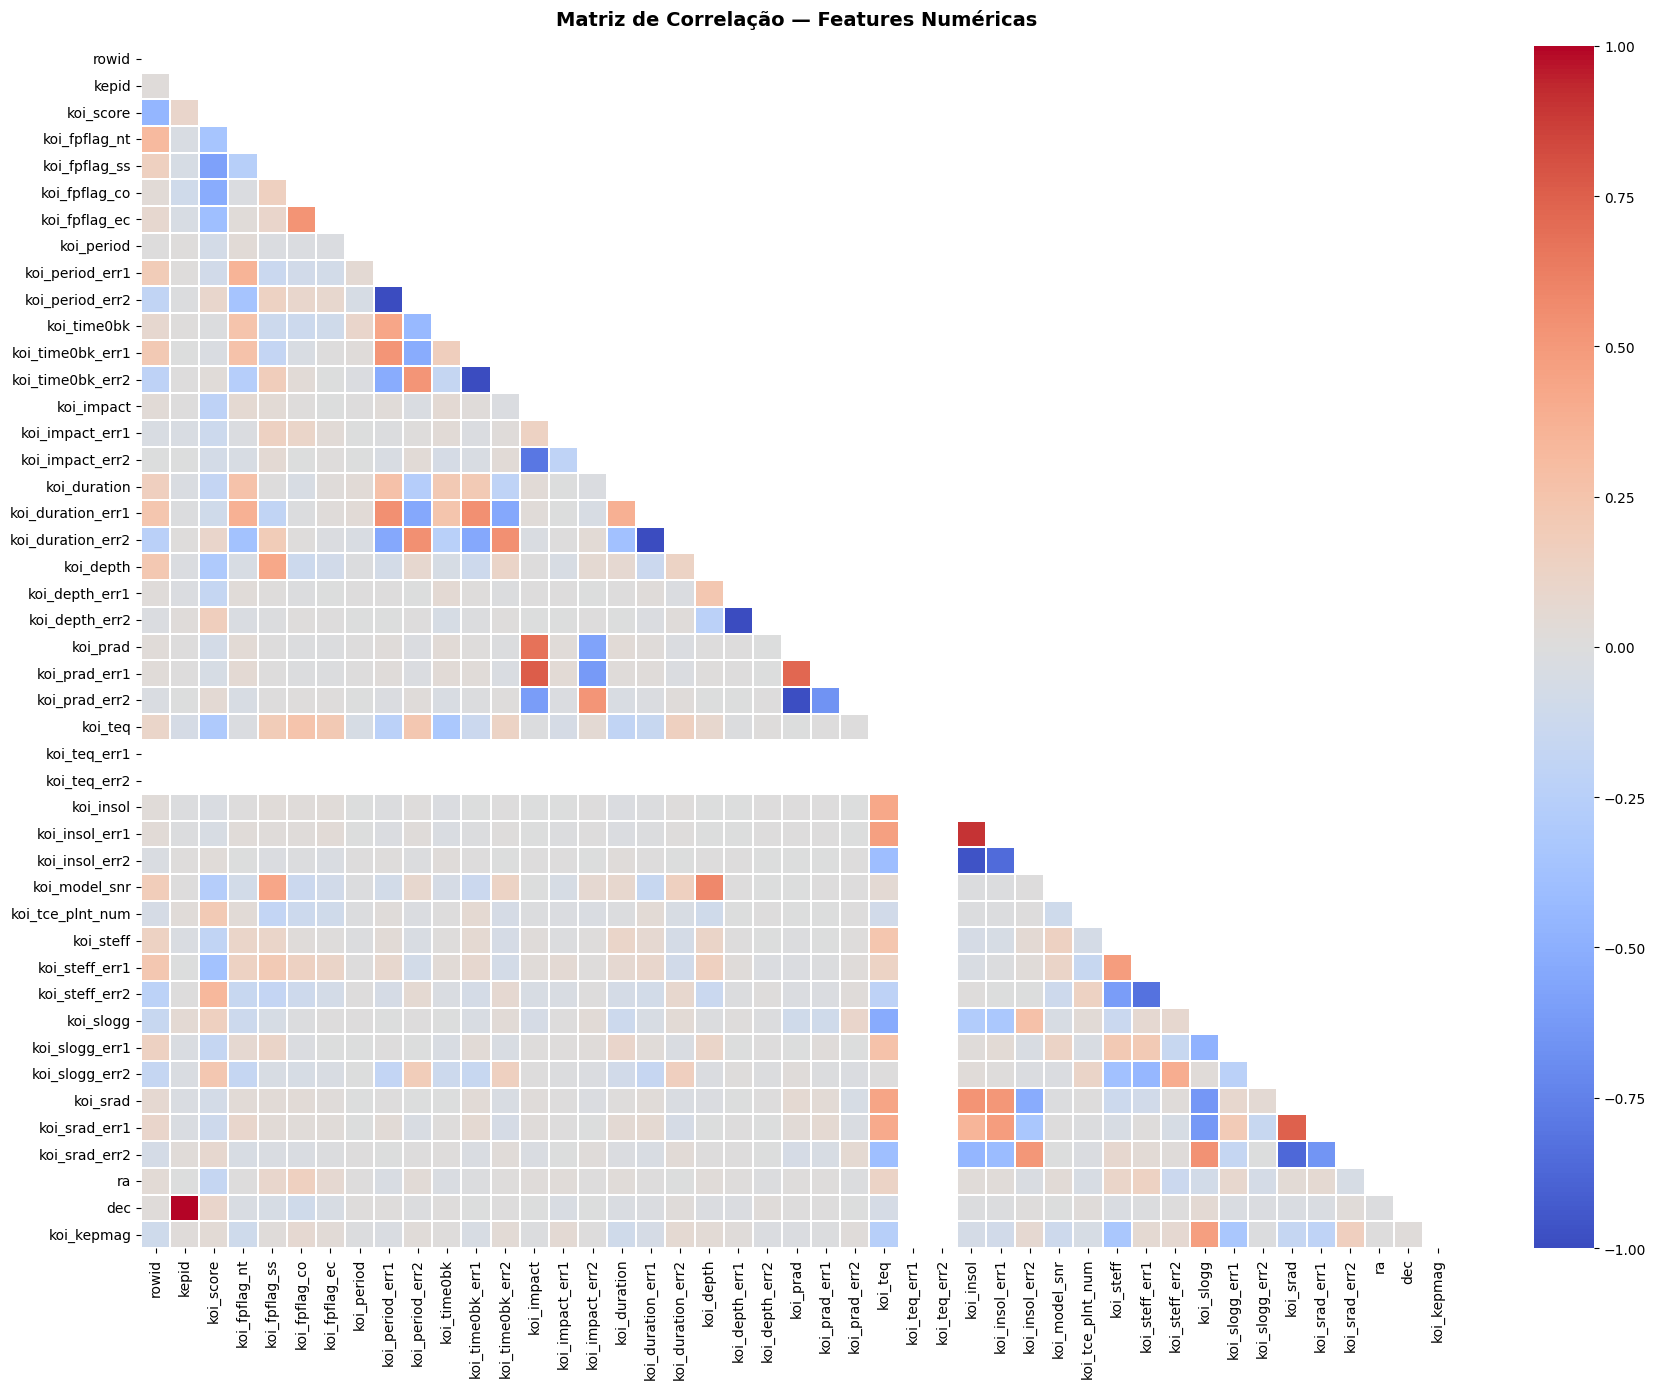

=== Pares com correlação > 0.95 ===
  kepid <-> dec: 0.99
  koi_period_err1 <-> koi_period_err2: -1.00
  koi_period_err2 <-> koi_period_err1: -1.00
  koi_time0bk_err1 <-> koi_time0bk_err2: -1.00
  koi_time0bk_err2 <-> koi_time0bk_err1: -1.00
  koi_duration_err1 <-> koi_duration_err2: -1.00
  koi_duration_err2 <-> koi_duration_err1: -1.00
  koi_depth_err1 <-> koi_depth_err2: -1.00
  koi_depth_err2 <-> koi_depth_err1: -1.00
  koi_prad <-> koi_prad_err2: -0.99
  koi_prad_err2 <-> koi_prad: -0.99
  koi_insol <-> koi_insol_err2: -0.97
  koi_insol_err2 <-> koi_insol: -0.97
  dec <-> kepid: 0.99


In [10]:
  # ============================================================
  # FASE 2 - Passo 3: Matriz de Correlação
  # ============================================================

  # Selecionamos apenas as colunas numéricas
  df_numerico = df.select_dtypes(include=[np.number])

  # Calculamos a correlação entre todas as colunas numéricas
  matriz_corr = df_numerico.corr()

  # Criamos uma máscara para esconder o triângulo superior (é espelho do inferior)
  mascara = np.triu(np.ones_like(matriz_corr, dtype=bool))

  fig, ax = plt.subplots(figsize=(18, 14))

  sns.heatmap(
      matriz_corr,
      mask=mascara,
      annot=False,       # não escrevemos os números (há colunas a mais, ficava ilegível)
      cmap="coolwarm",   # azul = correlação negativa, vermelho = correlação positiva
      vmin=-1, vmax=1,
      linewidths=0.3,
      ax=ax
  )

  ax.set_title("Matriz de Correlação — Features Numéricas", fontsize=14, fontweight="bold", pad=15)
  plt.tight_layout()
  plt.show()

  # Identificamos os pares com correlação muito alta (acima de 0.95)
  print("=== Pares com correlação > 0.95 ===")
  for col in matriz_corr.columns:
      for row in matriz_corr.index:
          if row != col:
              valor = matriz_corr.loc[row, col]
              if abs(valor) > 0.95:
                  print(f"  {col} <-> {row}: {valor:.2f}")

In [11]:
  # ============================================================
  # FASE 3 - Passo 1: Remover Colunas Inúteis
  # ============================================================

  # Colunas de identificação e texto — não têm valor físico
colunas_id = ["rowid", "kepid", "kepoi_name", "kepler_name", "koi_tce_delivname", "koi_pdisposition"]

  # Colunas _err2 — são espelhos das _err1 (correlação -1.00)
colunas_err2 = [col for col in df.columns if col.endswith("_err2")]

  # Colunas completamente vazias (0 valores não-nulos)
colunas_vazias = ["koi_teq_err1", "koi_teq_err2"]

  # Juntamos tudo numa lista só
colunas_a_remover = colunas_id + colunas_err2 + colunas_vazias

  # Removemos as colunas e guardamos num novo DataFrame
df_limpo = df.drop(columns=colunas_a_remover)

print(f"Colunas antes: {df.shape[1]}")
print(f"Colunas depois: {df_limpo.shape[1]}")
print(f"Colunas removidas: {len(colunas_a_remover)}")
print(f"\nColunas que restam:\n{list(df_limpo.columns)}")

Colunas antes: 50
Colunas depois: 32
Colunas removidas: 19

Colunas que restam:
['koi_disposition', 'koi_score', 'koi_fpflag_nt', 'koi_fpflag_ss', 'koi_fpflag_co', 'koi_fpflag_ec', 'koi_period', 'koi_period_err1', 'koi_time0bk', 'koi_time0bk_err1', 'koi_impact', 'koi_impact_err1', 'koi_duration', 'koi_duration_err1', 'koi_depth', 'koi_depth_err1', 'koi_prad', 'koi_prad_err1', 'koi_teq', 'koi_insol', 'koi_insol_err1', 'koi_model_snr', 'koi_tce_plnt_num', 'koi_steff', 'koi_steff_err1', 'koi_slogg', 'koi_slogg_err1', 'koi_srad', 'koi_srad_err1', 'ra', 'dec', 'koi_kepmag']


In [12]:
  # ============================================================                                                                                                                                                               
  # FASE 3 - Passo 2: Tratar Valores Nulos (NaN)
  # ============================================================

  # Verificamos quantos NaN existem em cada coluna
  nulos = df_limpo.isnull().sum()
  nulos = nulos[nulos > 0].sort_values(ascending=False)

  print("=== Colunas com valores nulos ===")
  print(nulos)
  print(f"\nTotal de linhas: {len(df_limpo)}")

=== Colunas com valores nulos ===
koi_score            1510
koi_slogg_err1        468
koi_srad_err1         468
koi_steff_err1        468
koi_time0bk_err1      454
koi_period_err1       454
koi_impact_err1       454
koi_duration_err1     454
koi_depth_err1        454
koi_impact            363
koi_teq               363
koi_depth             363
koi_prad              363
koi_prad_err1         363
koi_srad              363
koi_slogg             363
koi_model_snr         363
koi_steff             363
koi_tce_plnt_num      346
koi_insol             321
koi_insol_err1        321
koi_kepmag              1
dtype: int64

Total de linhas: 9564


In [13]:
# ============================================================
  # FASE 3 - Passo 2 (continuação): Preencher NaN com a Mediana
  # ============================================================

  # Para cada coluna com nulos, preenchemos com a mediana dessa coluna
# A mediana é o valor do meio quando ordenamos todos os valores
for coluna in df_limpo.columns:
    if df_limpo[coluna].isnull().sum() > 0:
        mediana = df_limpo[coluna].median()
        df_limpo[coluna] = df_limpo[coluna].fillna(mediana)

  # Confirmamos que não há mais nulos
total_nulos = df_limpo.isnull().sum().sum()
print(f"Total de valores nulos após limpeza: {total_nulos}")
print(f"Dimensões do dataset limpo: {df_limpo.shape}")

Total de valores nulos após limpeza: 0
Dimensões do dataset limpo: (9564, 32)


In [14]:
 # ============================================================
  # FASE 3 - Passo 3: Normalização das Features
  # ============================================================

from sklearn.preprocessing import MinMaxScaler

  # Separamos a coluna target do resto
  # X = tudo o que a IA vai usar para aprender (as features)
  # y = o que queremos prever (a classe)
X = df_limpo.drop(columns=["koi_disposition"])
y = df_limpo["koi_disposition"]

  # Criamos o normalizador — vai transformar cada coluna para o intervalo [0, 1]
scaler = MinMaxScaler()

  # Aplicamos a normalização e guardamos num novo DataFrame
X_normalizado = pd.DataFrame(
      scaler.fit_transform(X),
      columns=X.columns
  )

print("=== Antes da normalização ===")
print(X[["koi_period", "koi_impact", "koi_depth"]].describe().round(2))

print("\n=== Depois da normalização ===")
print(X_normalizado[["koi_period", "koi_impact", "koi_depth"]].describe().round(2))

=== Antes da normalização ===
       koi_period  koi_impact   koi_depth
count     9564.00     9564.00     9564.00
mean        75.67        0.73    22904.32
std       1334.74        3.28    80790.20
min          0.24        0.00        0.00
25%          2.73        0.21      166.80
50%          9.75        0.54      421.10
75%         40.72        0.88     1341.78
max     129995.78      100.81  1541400.00

=== Depois da normalização ===
       koi_period  koi_impact  koi_depth
count     9564.00     9564.00    9564.00
mean         0.00        0.01       0.01
std          0.01        0.03       0.05
min          0.00        0.00       0.00
25%          0.00        0.00       0.00
50%          0.00        0.01       0.00
75%          0.00        0.01       0.00
max          1.00        1.00       1.00


In [15]:
 # ============================================================
  # FASE 4 - Passo 1: Divisão Treino/Teste
  # ============================================================

from sklearn.model_selection import train_test_split

  # Dividimos os dados: 80% para treino, 20% para teste
  # random_state=42 garante que a divisão é sempre igual se corrermos o código outra vez
  # stratify=y garante que a proporção das classes é mantida nos dois conjuntos
X_train, X_test, y_train, y_test = train_test_split(
      X_normalizado, y,
      test_size=0.20,
      random_state=42,
      stratify=y
  )

print(f"Tamanho do conjunto de treino: {X_train.shape}")
print(f"Tamanho do conjunto de teste:  {X_test.shape}")

print(f"\nDistribuição no treino:")
print(y_train.value_counts())
print(f"\nDistribuição no teste:")
print(y_test.value_counts())

Tamanho do conjunto de treino: (7651, 31)
Tamanho do conjunto de teste:  (1913, 31)

Distribuição no treino:
koi_disposition
FALSE POSITIVE    4018
CONFIRMED         1834
CANDIDATE         1799
Name: count, dtype: int64

Distribuição no teste:
koi_disposition
FALSE POSITIVE    1005
CONFIRMED          459
CANDIDATE          449
Name: count, dtype: int64


In [16]:
# ============================================================
# FASE 4 - Passo 2: Treino do Random Forest
# ============================================================

from sklearn.ensemble import RandomForestClassifier

# Criamos o modelo com 500 árvores de decisão
# random_state=42 garante resultados reprodutíveis
# n_jobs=-1 usa todos os núcleos do processador para treinar mais rápido
modelo = RandomForestClassifier(
    n_estimators=500,
    random_state=42,
    n_jobs=-1
)

# Treinamos o modelo com os dados de treino
# O modelo vai aprender a associar as features (X_train) às classes (y_train)
print("A treinar o modelo... (pode demorar alguns segundos)")
modelo.fit(X_train, y_train)

print("Modelo treinado com sucesso!")
print(f"Número de árvores: {modelo.n_estimators}")
print(f"Número de features usadas: {modelo.n_features_in_}")

A treinar o modelo... (pode demorar alguns segundos)
Modelo treinado com sucesso!
Número de árvores: 500
Número de features usadas: 31


In [17]:
# ============================================================
# FASE 4 - Passo 3: Avaliação do Modelo
# ============================================================

from sklearn.metrics import classification_report, accuracy_score

# Usamos o modelo para prever as classes do conjunto de teste
# O modelo nunca viu estes dados durante o treino
y_pred = modelo.predict(X_test)

# Accuracy geral
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2%}\n")

# Relatório completo com Precision, Recall e F1 para cada classe
print("=== Relatório de Classificação ===")
print(classification_report(y_test, y_pred))

Accuracy: 90.96%

=== Relatório de Classificação ===
                precision    recall  f1-score   support

     CANDIDATE       0.83      0.80      0.81       449
     CONFIRMED       0.83      0.85      0.84       459
FALSE POSITIVE       0.98      0.99      0.98      1005

      accuracy                           0.91      1913
     macro avg       0.88      0.88      0.88      1913
  weighted avg       0.91      0.91      0.91      1913



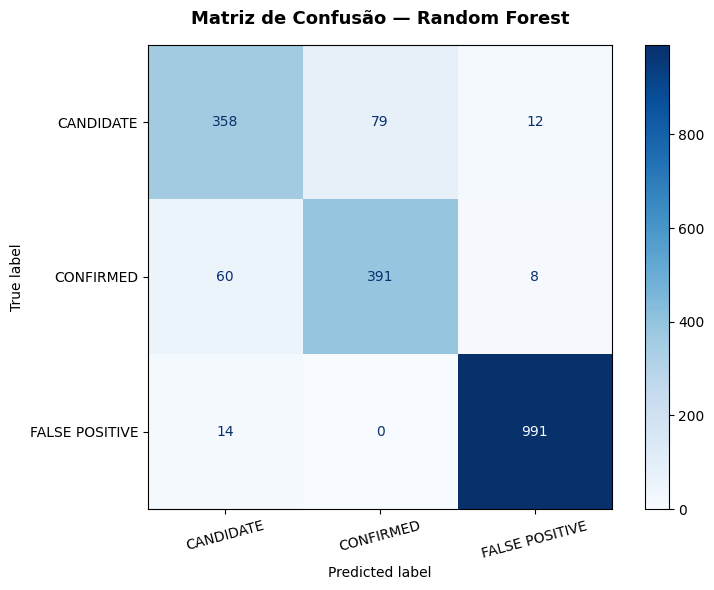

In [18]:
# ============================================================
# FASE 4 - Passo 4: Matriz de Confusão
# ============================================================

from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Calculamos a matriz de confusão
cm = confusion_matrix(y_test, y_pred, labels=["CANDIDATE", "CONFIRMED", "FALSE POSITIVE"])

# Visualizamos a matriz
fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["CANDIDATE", "CONFIRMED", "FALSE POSITIVE"]
)

disp.plot(ax=ax, colorbar=True, cmap="Blues")

ax.set_title("Matriz de Confusão — Random Forest", fontsize=13, fontweight="bold", pad=15)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [19]:
# ============================================================
# FASE 5 - Passo 1: Calcular Valores SHAP
# ============================================================

import shap

# Criamos o explicador SHAP para o nosso Random Forest
# O TreeExplainer é otimizado para modelos baseados em árvores
explicador = shap.TreeExplainer(modelo)

# Calculamos os valores SHAP para o conjunto de teste
# Isto pode demorar alguns segundos
print("A calcular valores SHAP...")
valores_shap = explicador.shap_values(X_test)

print("Concluído!")
print(f"Forma dos valores SHAP: {len(valores_shap)} classes")

A calcular valores SHAP...
Concluído!
Forma dos valores SHAP: 1913 classes


In [20]:
import numpy as np

print(f"Tipo: {type(valores_shap)}")

if isinstance(valores_shap, list):
    print(f"É uma lista com {len(valores_shap)} elementos")
    print(f"Shape de cada elemento: {valores_shap[0].shape}")
else:
    print(f"É um array com shape: {valores_shap.shape}")

Tipo: <class 'numpy.ndarray'>
É um array com shape: (1913, 31, 3)


Ordem das classes: ['CANDIDATE', 'CONFIRMED', 'FALSE POSITIVE']


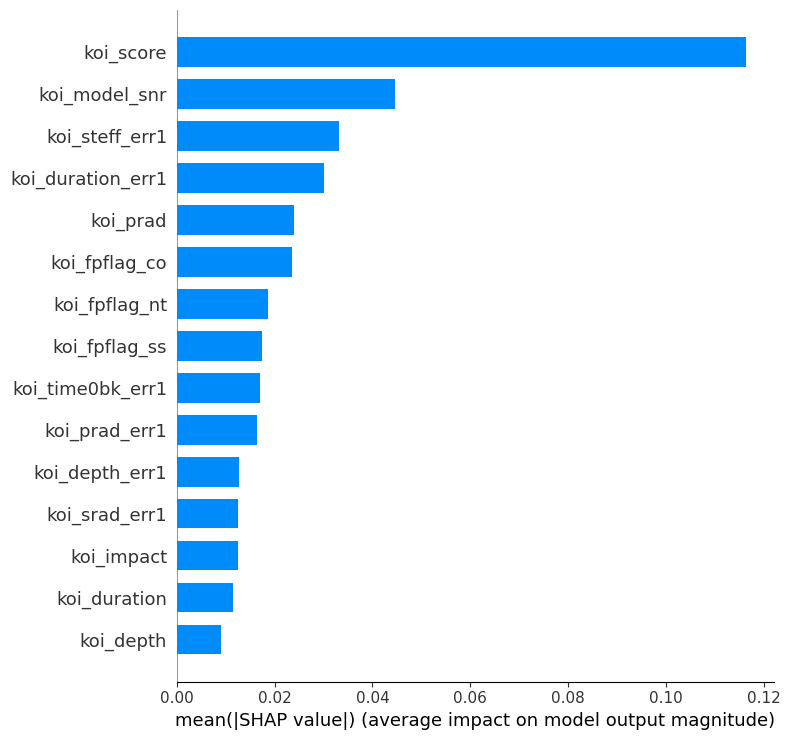

In [21]:
# ============================================================
# FASE 5 - Passo 2: Importância Global das Features
# ============================================================

# As classes estão nesta ordem no modelo
classes = list(modelo.classes_)
print(f"Ordem das classes: {classes}")

# Índice da classe CONFIRMED (queremos saber o que identifica um planeta real)
idx_confirmed = classes.index("CONFIRMED")

# Extraímos os valores SHAP apenas para a classe CONFIRMED
shap_confirmed = valores_shap[:, :, idx_confirmed]

# Gráfico de importância global (summary plot)
shap.summary_plot(
    shap_confirmed,
    X_test,
    plot_type="bar",
    max_display=15,
    show=True
)

Índice da estrela escolhida: 7
Classe real:      CONFIRMED
Classe prevista:  CONFIRMED


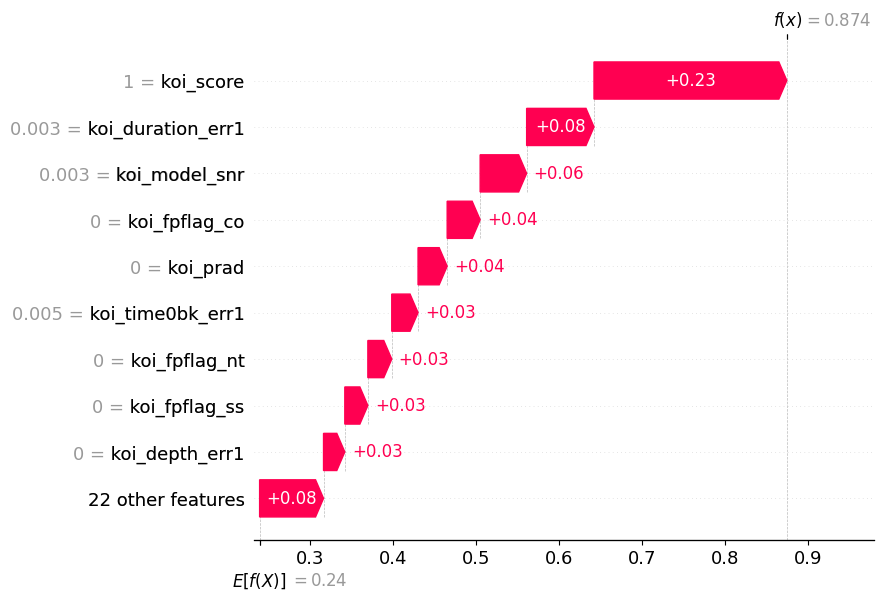

In [22]:
# ============================================================
# FASE 5 - Passo 3: Explicação Local — Uma Estrela Específica
# ============================================================

# Escolhemos a primeira observação do conjunto de teste
# que foi classificada como CONFIRMED
indices_confirmed = [i for i, pred in enumerate(y_pred) if pred == "CONFIRMED"]
idx_estrela = indices_confirmed[0]

print(f"Índice da estrela escolhida: {idx_estrela}")
print(f"Classe real:      {y_test.iloc[idx_estrela]}")
print(f"Classe prevista:  {y_pred[idx_estrela]}")

# Extraímos os valores SHAP desta estrela para a classe CONFIRMED
shap_estrela = valores_shap[idx_estrela, :, idx_confirmed]

# Gráfico waterfall — mostra como cada feature empurrou a decisão
shap.waterfall_plot(
    shap.Explanation(
        values=shap_estrela,
        base_values=explicador.expected_value[idx_confirmed],
        data=X_test.iloc[idx_estrela],
        feature_names=list(X_test.columns)
    )
)